In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import os
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

In [67]:
# Basic quantities, loading and converting to coordinates on Galactic plane

## Test 1: Mass > 1e4. Can work well but has issues with Perseus arm. Not enough points exist to fit the other side of the kink.
## Can be aleviated if I reduced min_point son the fitting functions (least squares and Huber loss) from 20 to 1 or 2

## Test 2: Complete. Can work well but has issues with Perseus arm. Not enough points exist to fit the other side of the kink.
## Can be aleviated if I reduced min_point son the fitting functions (least squares and Huber loss) from 20 to 1 or 2


R0 = 8.15

df_2 = pd.read_csv('Full_test_catalogue.csv')


#mask = df_2['M_13CO_X_Sol'] > 10 ** 5
#mask= df_2['M_13CO_X_Sol'] > 10 ** 4
mask = (df_2['Mass'] / df_2['final_distance'] ** 2) > 75.7
#mask = df_2['Mass'] > 10 ** 4

df_2 = df_2[mask]

l = np.radians(df_2["x_cen"].to_numpy())
b = np.radians(df_2["y_cen"].to_numpy())
d = df_2["final_distance"].to_numpy()

X = d * np.cos(b) * np.sin(l)
Y = R0 - d * np.cos(b) * np.cos(l)

R = np.hypot(X, Y)

# Reid azimuth convention
beta = np.degrees(np.arctan2(X, Y))

df_2["X_kpc"] = X
df_2["Y_kpc"] = Y
df_2["R_kpc"] = R
df_2["beta_deg"] = beta
df_2["ln_R"] = np.log(R)

In [68]:
# Old function from Mopra_spiral_arms_Reid.py

def reid_arm(name, n=2000, extend_low=0, extend_high=0,
             params=None):

    if params is None:
        params = parameters

    bmin, bmax, bkink, Rkink, p_low, p_high = params[name]

    beta = np.linspace(
        bmin - extend_low,
        bmax + extend_high,
        n
    )

    pitch = np.where(beta <= bkink, p_low, p_high)

    R = Rkink * np.exp(
        -np.radians(beta - bkink)
        * np.tan(np.radians(pitch))
    )

    X = R * np.sin(np.radians(beta))
    Y = R * np.cos(np.radians(beta))

    original = (beta >= bmin) & (beta <= bmax)

    return {
        "beta": beta,
        "R": R,
        "X": X,
        "Y": Y,
        "original": original
    }

parameters = {
    "3-kpc":   (15, 18, 15, 3.52, -4.2, -4.2),
    "Norma":   (5, 54, 18, 4.46, -1.0, 19.5),
    "Sct-Cen": (0, 104, 23, 4.91, 14.1, 12.1),
    "Sgr-Car": (2, 97, 24, 6.04, 17.1, 1.0),
    "Local":   (-8, 34, 9, 8.26, 11.4, 11.4),
    "Perseus": (-23, 115, 40, 8.87, 10.3, 8.7),
    "Outer":   (-16, 71, 18, 12.24, 3.0, 9.4),
}

# Fill these with verified Reid (2019) width values, in kpc
arm_widths = {
    "Norma": 0.14,
    "Sct-Cen" : 0.23,
    "Sgr-Car" : 0.27,
    "Perseus" : 0.35,
    "3-kpc"   : 0.18
}

In [69]:
# Assigning clouds to arms using KD Tree

arm_names = ["Norma", "Sct-Cen", "Sgr-Car", "Perseus", "3-kpc"]

colours = {
    "Norma": "red",
    "Sct-Cen": "blue",
    "Sgr-Car": "purple",
    "Perseus": "black",
    "3-kpc": "orange"
}

# Generate all four arms
extended_arms = {
    name: reid_arm(
        name,
        extend_low  = 130,
        extend_high =130
    )
    for name in arm_names
}

# Catalogue coordinates
cloud_xy = df_2[["X_kpc", "Y_kpc"]].to_numpy(dtype=float)  # Collect the coordinates of each cloud on the (X,Y) Galactic plane
valid = np.isfinite(cloud_xy).all(axis=1)

# Calculate distances to each arm
for name, arm in extended_arms.items():

    arm_xy = np.column_stack([
        arm["X"],
        arm["Y"]
    ])  # Collect the points making up each arm on the Galactic plane

    tree = cKDTree(arm_xy)  # Create the KD tree

    distances = np.full(len(df_2), np.nan)

    distances[valid], _ = tree.query(cloud_xy[valid]) 
    # distances: the distance, in kpc, from each cloud to the nearest sampled point on that arm.
    # indices: the index of that nearest arm point within arm_xy.

    df_2[f"dist_{name}_kpc"] = distances

# Identify nearest arm
distance_columns = [
    f"dist_{name}_kpc" for name in arm_names
]

distance_matrix = df_2[distance_columns].to_numpy()

closest_index = np.full(len(df_2), -1, dtype=int)
closest_distance = np.full(len(df_2), np.nan)

closest_index[valid] = np.argmin(
    distance_matrix[valid], axis=1  # Find arm with lowest distance
)                                  

closest_distance[valid] = np.min(
    distance_matrix[valid], axis=1
)

df_2["nearest_arm"] = [
    arm_names[i] if i >= 0 else None
    for i in closest_index
]

df_2["arm_distance_kpc"] = closest_distance

# Apply an initial association threshold
# Clouds will not be associated if their distance is higher than this, 3 * width
n_sigma = 3.0

df_2["assigned_arm"] = "Unassigned"

for name in arm_names:

    mask = (
        (df_2["nearest_arm"] == name)
        & (df_2["arm_distance_kpc"] <= n_sigma * arm_widths[name])
    )

    df_2.loc[mask, "assigned_arm"] = name

print(df_2["assigned_arm"].value_counts())

assigned_arm
Sct-Cen       553
Sgr-Car       357
Unassigned    217
Norma         188
3-kpc         101
Perseus        74
Name: count, dtype: int64


In [70]:
# Issue discovered later: Turn azimuth to 360 degrees to avoid problems
# Preserve the original wrapped azimuths
df_2["beta_unwrapped_deg"] = df_2["beta_deg"].copy()

# Record the winding number for diagnostic purposes
df_2["beta_winding"] = np.nan

for name in arm_names:

    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["X_kpc"])
        & np.isfinite(df_2["Y_kpc"])
        & np.isfinite(df_2["beta_deg"])
    ]

    if subset.empty:
        continue

    # Original extended Reid curve
    arm = extended_arms[name]

    arm_xy = np.column_stack([
        arm["X"],
        arm["Y"]
    ])

    arm_beta = np.asarray(arm["beta"])

    # Remove any invalid arm points
    valid = (
        np.isfinite(arm_xy).all(axis=1)
        & np.isfinite(arm_beta)
    )

    arm_xy = arm_xy[valid]
    arm_beta = arm_beta[valid]

    if len(arm_beta) == 0:
        continue

    # Find nearest Reid-arm point for each cloud
    tree = cKDTree(arm_xy)

    cloud_xy = subset[["X_kpc", "Y_kpc"]].to_numpy()

    distances, indices = tree.query(cloud_xy)

    beta_nearest = arm_beta[indices]

    # Cloud's original wrapped azimuth
    beta_wrapped = subset["beta_deg"].to_numpy()

    # Find the integer winding that matches the Reid arm
    winding = np.rint(
        (beta_nearest - beta_wrapped) / 360.0
    ).astype(int)

    # Corrected cloud azimuth
    beta_unwrapped = beta_wrapped + 360.0 * winding

    # Store results
    df_2.loc[
        subset.index, "beta_unwrapped_deg"
    ] = beta_unwrapped

    df_2.loc[
        subset.index, "beta_winding"
    ] = winding

# Correct remaining negative-beta Perseus clouds
# Only if their intended branch is the positive continuation

#mask = (
#    (df_2["assigned_arm"] == "Perseus")
#    & (df_2["beta_unwrapped_deg"] < 0)
#)

#print(f"Correcting {mask.sum()} Perseus clouds")

#df_2.loc[mask, "beta_unwrapped_deg"] = (
#    df_2.loc[mask, "beta_deg"] + 360.0
#)

#df_2.loc[mask, "beta_winding"] = 1

# Replace wrapped beta with corrected beta
#df_2["beta_deg"] = df_2["beta_unwrapped_deg"].copy()

# Verify
#print(
#    "Remaining negative Perseus azimuths:",
#    (
#        (df_2["assigned_arm"] == "Perseus")
#        & (df_2["beta_deg"] < 0)
#    ).sum()
#)

In [71]:
## Add arm asssignments and distances to the dataframe

# Distances already calculated using KD-trees
distance_columns = [f"dist_{name}_kpc" for name in arm_names]

distance_matrix = df_2[distance_columns].to_numpy(dtype=float)

width_array = np.array([arm_widths[name] for name in arm_names])

# Normalize by arm width
normalized_distances = distance_matrix / width_array[None, :]

# Save normalized distances, called z
for j, name in enumerate(arm_names):
    df_2[f"z_{name}"] = normalized_distances[:, j]

# Check

valid = np.isfinite(normalized_distances).all(axis=1)

best_index = np.full(len(df_2), -1, dtype=int)
best_z = np.full(len(df_2), np.nan)

best_index[valid] = np.argmin(
    normalized_distances[valid],
    axis=1
)

best_z[valid] = np.min(
    normalized_distances[valid],
    axis=1
)

df_2["assigned_arm"] = "Unassigned"
df_2["arm_z"] = best_z

for j, name in enumerate(arm_names):
    mask = (best_index == j) & (best_z <= n_sigma)
    df_2.loc[mask, "assigned_arm"] = name

print(df_2["assigned_arm"].value_counts())

# Check

sorted_z = np.sort(normalized_distances, axis=1)

df_2["second_best_z"] = np.where(
    valid, sorted_z[:, 1], np.nan
)

df_2["arm_separation_z"] = (
    df_2["second_best_z"] - df_2["arm_z"]
)

print(
    df_2[
        ["Universal_ID", "assigned_arm",
         "arm_z", "second_best_z", "arm_separation_z"]
    ].head(10)
)
# Measure if 2 arms well approach a source. A large arm_separation means a good first choice.

assigned_arm
Sct-Cen       561
Sgr-Car       359
Unassigned    206
Norma         177
3-kpc         106
Perseus        81
Name: count, dtype: int64
    Universal_ID assigned_arm      arm_z  second_best_z  arm_separation_z
0              1   Unassigned  12.317722      18.386406          6.068684
1              2   Unassigned   7.524282      12.166083          4.641801
2              3   Unassigned   6.811894      11.848539          5.036644
3              4        3-kpc   0.898390       7.088126          6.189735
4              5      Sgr-Car   2.840847       6.724518          3.883671
5              6      Sct-Cen   2.133326       2.150268          0.016942
6              7      Sgr-Car   0.365999       6.419067          6.053068
7              8   Unassigned   3.261256       6.394053          3.132797
8              9      Sgr-Car   2.053421       7.346399          5.292978
10            11      Sgr-Car   0.989087       4.736497          3.747411


In [72]:
indices = [1385, 1759, 1765]

arm = extended_arms["Perseus"]

arm_xy = np.column_stack([arm["X"], arm["Y"]])
arm_beta = np.asarray(arm["beta"])

valid = np.isfinite(arm_xy).all(axis=1) & np.isfinite(arm_beta)

tree = cKDTree(arm_xy[valid])

cloud_xy = df_2.loc[indices, ["X_kpc", "Y_kpc"]].to_numpy()

distances, nearest_indices = tree.query(cloud_xy)

beta_nearest = arm_beta[valid][nearest_indices]
beta_wrapped = df_2.loc[indices, "beta_deg"].to_numpy()

winding = np.rint(
    (beta_nearest - beta_wrapped) / 360.0
).astype(int)

print(
    pd.DataFrame({
        "beta_wrapped": beta_wrapped,
        "beta_nearest_arm": beta_nearest,
        "winding": winding,
        "distance_kpc": distances
    }, index=indices)
)

indices = [1385, 1759, 1765]

# Assign the windings calculated in the diagnostic
df_2.loc[indices, "beta_winding"] = winding

# Update their unwrapped azimuths
df_2.loc[indices, "beta_unwrapped_deg"] = (
    df_2.loc[indices, "beta_deg"]
    + 360.0 * df_2.loc[indices, "beta_winding"]
)

# Verify the dataframe was updated
print(
    df_2.loc[
        indices,
        ["beta_deg", "beta_unwrapped_deg", "beta_winding", "arm_separation_z"]
    ]
)

      beta_wrapped  beta_nearest_arm  winding  distance_kpc
1385   -104.097836        245.000000        1      0.988417
1759   -163.160622        198.609805        1      1.020023
1765   -165.684829        196.021511        1      0.955345
        beta_deg  beta_unwrapped_deg  beta_winding  arm_separation_z
1385 -104.097836          255.902164           1.0          3.810206
1759 -163.160622          196.839378           1.0          0.529664
1765 -165.684829          194.315171           1.0          0.341069


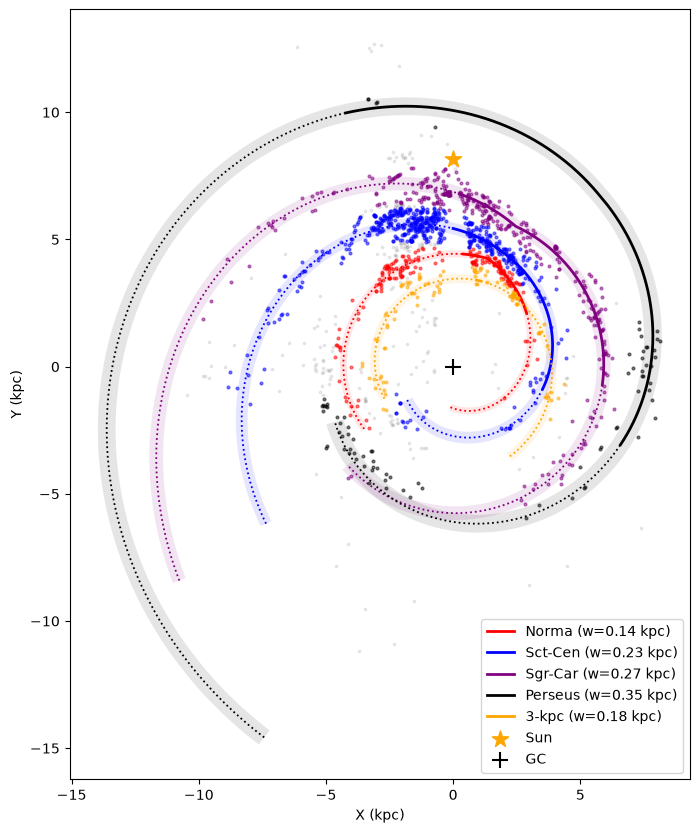

In [73]:
# Plot arms assignment ver.1

fig, ax = plt.subplots(figsize=(10, 10))

for name, arm in extended_arms.items():

    beta = arm["beta"]
    X = arm["X"]
    Y = arm["Y"]

    bmin, bmax, *_ = parameters[name]

    original = (beta >= bmin) & (beta <= bmax)
    extension_low = beta < bmin
    extension_high = beta > bmax

    # Arm width (kpc)
    w = arm_widths[name]

    # Tangent vector along the spiral
    dx = np.gradient(X)
    dy = np.gradient(Y)

    length = np.hypot(dx, dy)

    # Unit normal vector
    nx = -dy / length
    ny = dx / length

    # Boundaries at +/- one arm width
    X_upper = X + w * nx
    Y_upper = Y + w * ny

    X_lower = X - w * nx
    Y_lower = Y - w * ny

    # Fill the band between the two boundaries
    band_x = np.concatenate([X_upper, X_lower[::-1]])
    band_y = np.concatenate([Y_upper, Y_lower[::-1]])

    ax.fill(
        band_x,
        band_y,
        color=colours[name],
        alpha=0.10,
        linewidth=0,
        zorder=1
    )

    # Original arm centreline
    ax.plot(
        X[original],
        Y[original],
        color=colours[name],
        lw=2,
        ls="-",
        label=f"{name} (w={w:.2f} kpc)",
        zorder=3
    )

    # Plot extensions separately to avoid artificial connections
    for mask in [extension_low, extension_high]:

        ax.plot(
            X[mask],
            Y[mask],
            color=colours[name],
            lw=1.3,
            ls=":",
            zorder=3
        )

# Catalogue clouds, coloured by assigned arm
for name in arm_names:

    subset = df_2[df_2["assigned_arm"] == name]

    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=4,
        color=colours[name],
        alpha=0.5,
        rasterized=True,
        zorder=4
    )

# Unassigned clouds
unassigned = df_2[df_2["assigned_arm"] == "Unassigned"]

ax.scatter(
    unassigned["X_kpc"],
    unassigned["Y_kpc"],
    s=3,
    color="grey",
    alpha=0.15,
    rasterized=True,
    zorder=2
)

# Sun and Galactic Centre
ax.scatter(0, R0, marker="*", s=150,
           color="orange", zorder=5, label="Sun")

ax.scatter(0, 0, marker="+", s=120,
           color="black", zorder=5, label="GC")

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_aspect("equal")
ax.legend()

plt.show()

In [52]:
# Check
print(
    df_2.groupby("assigned_arm")["arm_z"]
    .agg(["count", "median", "mean"])
)

              count    median      mean
assigned_arm                           
3-kpc           106  0.944409  1.220925
Norma           177  1.088899  1.222174
Perseus          81  1.107409  1.163092
Sct-Cen         561  1.116673  1.199648
Sgr-Car         359  0.767870  0.971783
Unassigned      206  3.911632  4.723910


In [53]:
## Fit clouds to double Reid arm, with kink and 2 pitch angles

def fit_reid_arm(df, name, parameters, min_points=2):

    bmin, bmax, bkink, Rkink, p_low, p_high = parameters[name] # Looks like we are feeding Rkink, bkink into this and fit for R,b

    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_unwrapped_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ].copy()

    if len(subset) < min_points:
        return None

    # Azimuth relative to Reid kink, in radians
    beta = np.radians(subset["beta_unwrapped_deg"].to_numpy())
    beta_kink = np.radians(bkink)

    x = beta - beta_kink
    y = np.log(subset["R_kpc"].to_numpy())

    # Continuous piecewise-linear model, looks like with high and low we fit for under and over the kink
    x_low = np.minimum(x, 0.0)
    x_high = np.maximum(x, 0.0)

    A = np.column_stack([  ## A has the parameters for both high and low, before and after kink
        np.ones_like(x),
        x_low,
        x_high
    ])   

    # Ordinary least squares for the first experiment
    coefficients, residuals, rank, singular_values = (  ## Fitting for A containing high and low, coefficients are a, mhigh and mlow
        np.linalg.lstsq(A, y, rcond=None)
    )

    if rank < 3:
        return None

    a, m_low, m_high = coefficients

    return {
        "name": name,
        "N": len(subset),
        "Rkink_fit": np.exp(a),
        "pitch_low_fit": np.degrees(np.arctan(-m_low)),
        "pitch_high_fit": np.degrees(np.arctan(-m_high)),
        "Rkink_Reid": Rkink,
        "pitch_low_Reid": p_low,
        "pitch_high_Reid": p_high
    }


fit_results = []

for name in arm_names:

    result = fit_reid_arm(df_2, name, parameters)
    
    if result is not None:
        fit_results.append(result)

fit_table = pd.DataFrame(fit_results)

print(fit_table.round(3).to_string(index=False))

   name   N  Rkink_fit  pitch_low_fit  pitch_high_fit  Rkink_Reid  pitch_low_Reid  pitch_high_Reid
  Norma 177      4.457         -0.458          18.779        4.46            -1.0             19.5
Sct-Cen 561      4.995         12.943          11.040        4.91            14.1             12.1
Sgr-Car 359      5.940         17.156           0.235        6.04            17.1              1.0
Perseus  81      8.543         13.068           8.556        8.87            10.3              8.7
  3-kpc 106      3.657         -5.286          -2.644        3.52            -4.2             -4.2


In [54]:
fit_results

[{'name': 'Norma',
  'N': 177,
  'Rkink_fit': np.float64(4.456654781128819),
  'pitch_low_fit': np.float64(-0.45776311666441294),
  'pitch_high_fit': np.float64(18.779304655732652),
  'Rkink_Reid': 4.46,
  'pitch_low_Reid': -1.0,
  'pitch_high_Reid': 19.5},
 {'name': 'Sct-Cen',
  'N': 561,
  'Rkink_fit': np.float64(4.9954687275096274),
  'pitch_low_fit': np.float64(12.943225782722644),
  'pitch_high_fit': np.float64(11.04019494129158),
  'Rkink_Reid': 4.91,
  'pitch_low_Reid': 14.1,
  'pitch_high_Reid': 12.1},
 {'name': 'Sgr-Car',
  'N': 359,
  'Rkink_fit': np.float64(5.939840896078051),
  'pitch_low_fit': np.float64(17.15551936111548),
  'pitch_high_fit': np.float64(0.23525081076186058),
  'Rkink_Reid': 6.04,
  'pitch_low_Reid': 17.1,
  'pitch_high_Reid': 1.0},
 {'name': 'Perseus',
  'N': 81,
  'Rkink_fit': np.float64(8.543184980663398),
  'pitch_low_fit': np.float64(13.068356374856544),
  'pitch_high_fit': np.float64(8.556348546475492),
  'Rkink_Reid': 8.87,
  'pitch_low_Reid': 10.3,

In [55]:
## Load fit parameters

fitted_parameters = parameters.copy()

for result in fit_results:

    name = result["name"]

    bmin, bmax, bkink, _, _, _ = parameters[name]

    fitted_parameters[name] = (
        bmin,
        bmax,
        bkink,
        result["Rkink_fit"],
        result["pitch_low_fit"],
        result["pitch_high_fit"]
    )

In [56]:
# Create fitted arms

fitted_arms = {
    name: reid_arm(
        name,
        extend_low=130,
        extend_high=130,
        params=fitted_parameters
    )
    for name in arm_names
}

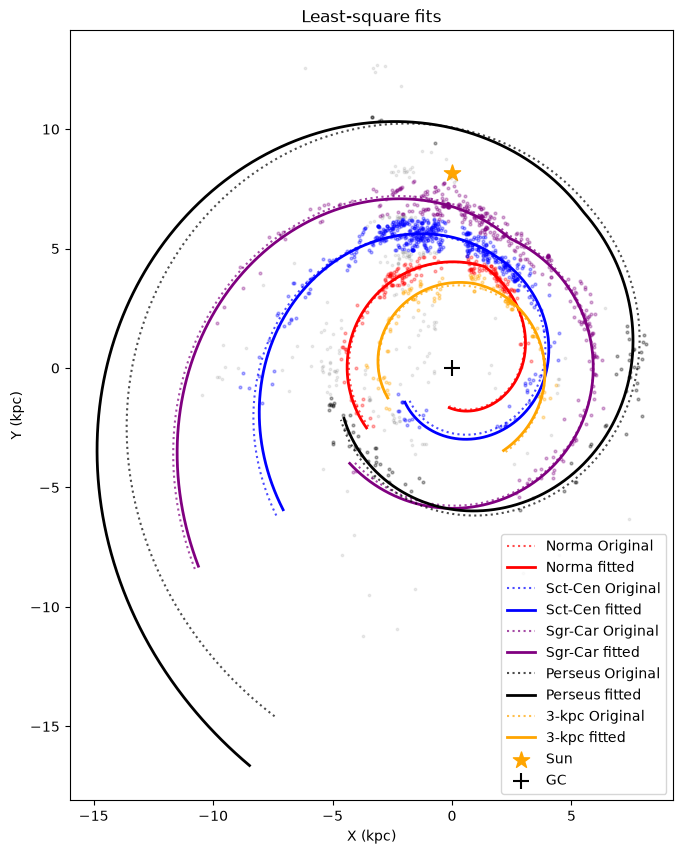

In [57]:
# Plot fitted arms

fig, ax = plt.subplots(figsize=(10, 10))

for name in arm_names:

    original = extended_arms[name]
    fitted = fitted_arms[name]

    # Initial Reid geometry
    ax.plot(
        original["X"],
        original["Y"],
        color=colours[name],
        ls=":",
        lw=1.5,
        alpha=0.7,
        label = f"{name} Original"
    )

    # Newly fitted geometry
    ax.plot(
        fitted["X"],
        fitted["Y"],
        color=colours[name],
        ls="-",
        lw=2,
        label=f"{name} fitted"
    )

    # Clouds assigned to this arm
    subset = df_2[df_2["assigned_arm"] == name]

    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=4,
        color=colours[name],
        alpha=0.3,
        rasterized=True
    )

unassigned = df_2[df_2["assigned_arm"] == "Unassigned"]

ax.scatter(
    unassigned["X_kpc"],
    unassigned["Y_kpc"],
    s=3,
    color="grey",
    alpha=0.15,
    rasterized=True,
    zorder=2
)

ax.scatter(0, R0, marker="*", s=150, color="orange", label="Sun")
ax.scatter(0, 0, marker="+", s=120, color="black", label="GC")

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_aspect("equal")
ax.set_title('Least-square fits')
ax.legend()
plt.show()

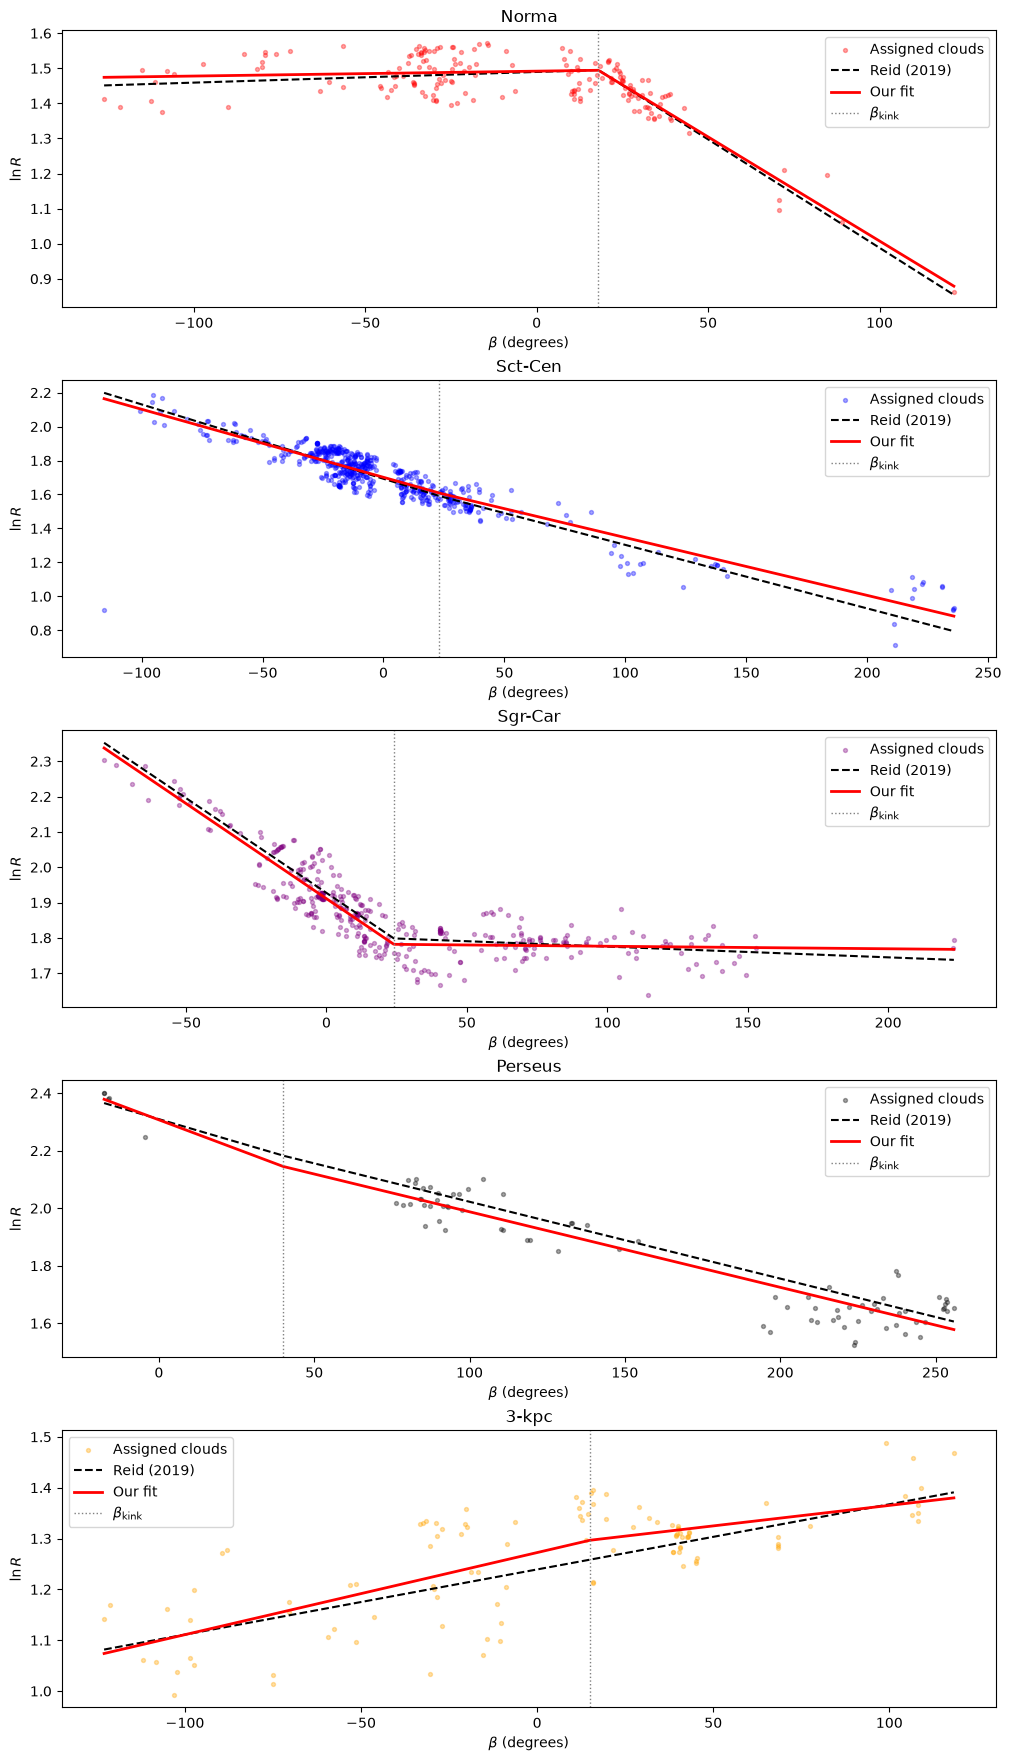

In [58]:
# Check fits of arms vs points (including both sides of the kink)

fig, axes = plt.subplots(
    len(arm_names), 1,
    figsize=(10, 3.5 * len(arm_names)),
    constrained_layout=True
)

# Store fitted results for easy lookup
fit_lookup = {result["name"]: result for result in fit_results}

for ax, name in zip(axes, arm_names):

    # Clouds assigned to this arm
    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["beta_unwrapped_deg"])
        & np.isfinite(df_2["R_kpc"])
        & (df_2["R_kpc"] > 0)
    ]

    if subset.empty:
        ax.set_title(f"{name} (no assigned clouds)")
        continue

    beta_cloud = subset["beta_unwrapped_deg"].to_numpy()
    lnR_cloud = np.log(subset["R_kpc"].to_numpy())

    # Original Reid parameters
    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Grid covering the observed azimuth interval
    beta_grid = np.linspace(
        beta_cloud.min(),
        beta_cloud.max(),
        500
    )

    # Reid model: use the appropriate pitch angle on each side
    pitch_reid = np.where(
        beta_grid <= bkink,
        p_low,
        p_high
    )

    lnR_reid = (
        np.log(Rkink)
        - np.radians(beta_grid - bkink)
        * np.tan(np.radians(pitch_reid))
    )

    # Plot assigned clouds
    ax.scatter(
        beta_cloud,
        lnR_cloud,
        s=8,
        color=colours[name],
        alpha=0.35,
        label="Assigned clouds"
    )

    # Plot Reid model
    ax.plot(
        beta_grid,
        lnR_reid,
        "k--",
        lw=1.5,
        label="Reid (2019)"
    )

    # Plot our fitted model, if available
    result = fit_lookup.get(name)

    if result is not None:

        pitch_fit = np.where(
            beta_grid <= bkink,
            result["pitch_low_fit"],
            result["pitch_high_fit"]
        )

        lnR_fit = (
            np.log(result["Rkink_fit"])
            - np.radians(beta_grid - bkink)
            * np.tan(np.radians(pitch_fit))
        )

        ax.plot(
            beta_grid,
            lnR_fit,
            color="red",
            lw=2,
            label="Our fit"
        )

    # Mark Reid's kink if it lies within the plotted interval
    if beta_grid.min() <= bkink <= beta_grid.max():
        ax.axvline(
            bkink,
            color="gray",
            ls=":",
            lw=1,
            label=r"$\beta_{\rm kink}$"
        )

    ax.set_title(name)
    ax.set_xlabel(r"$\beta$ (degrees)")
    ax.set_ylabel(r"$\ln R$")

    ax.legend()

plt.show()

In [34]:
# Turns out outliers impact the fit negatively even for the full sample. 
# Try a different fit, Huber loss. Similar to least squares but less sensitive to outliers

def fit_robust_arm(
    df, name, parameters,
    min_points=20,
    min_side_points=2,
    f_scale=0.03
):

    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Select clouds assigned to this arm
    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_unwrapped_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ]

    if len(subset) < min_points:
        print('Not enough points!', name)
        return None

    beta = subset["beta_unwrapped_deg"].to_numpy(dtype=float)
    R = subset["R_kpc"].to_numpy(dtype=float)

    # Angular distance from kink, in radians
    x = np.radians(beta - bkink)
    y = np.log(R)

    # Separate the two sides of the kink
    x_low = np.minimum(x, 0.0)
    x_high = np.maximum(x, 0.0)

    n_low = np.sum(x <= 0)
    n_high = np.sum(x > 0)

    # Require adequate coverage on both sides
    if n_low < min_side_points or n_high < min_side_points:
        print('Not enough side points!', name, n_low, n_high)
        return None

    # Design matrix for continuous piecewise-linear model
    A = np.column_stack([
        np.ones_like(x),
        x_low,
        x_high
    ])

    # Initial solution from ordinary least squares
    theta0 = np.linalg.lstsq(A, y, rcond=None)[0]

    # Residuals in ln(R)
    def residuals(theta):
        return y - A @ theta

    # Robust fitting with Huber loss
    result = least_squares(
        residuals,
        x0=theta0,
        loss="huber",
        f_scale=f_scale
    )

    if not result.success:
        return None

    a_fit, m_low_fit, m_high_fit = result.x

    return {
        "name": name,
        "N": len(subset),
        "N_low": int(n_low),
        "N_high": int(n_high),

        "Rkink_fit": np.exp(a_fit),

        "pitch_low_fit": np.degrees(
            np.arctan(-m_low_fit)
        ),

        "pitch_high_fit": np.degrees(
            np.arctan(-m_high_fit)
        ),

        "Rkink_Reid": Rkink,
        "pitch_low_Reid": p_low,
        "pitch_high_Reid": p_high
    }

In [36]:
# Robust Huber fitting for all arms

robust_results = []

for name in arm_names:

    robust_result = fit_robust_arm(
        df_2,
        name,
        parameters,
        min_points=20,
        min_side_points=2,
        f_scale=0.03
    )

    if robust_result is not None:
        robust_results.append(robust_result)

robust_table = pd.DataFrame(robust_results)

if not robust_table.empty:
    print(robust_table.round(3).to_string(index=False))
else:
    print("No arms met the fitting requirements.")

   name   N  N_low  N_high  Rkink_fit  pitch_low_fit  pitch_high_fit  Rkink_Reid  pitch_low_Reid  pitch_high_Reid
  Norma 177    118      59      4.458         -0.297          19.072        4.46            -1.0             19.5
Sct-Cen 561    449     112      4.928         14.487          10.556        4.91            14.1             12.1
Sgr-Car 359    222     137      5.946         17.253           0.093        6.04            17.1              1.0
Perseus  81      5      76      8.536         13.620           8.574        8.87            10.3              8.7
  3-kpc 106     56      50      3.683         -5.727          -1.655        3.52            -4.2             -4.2


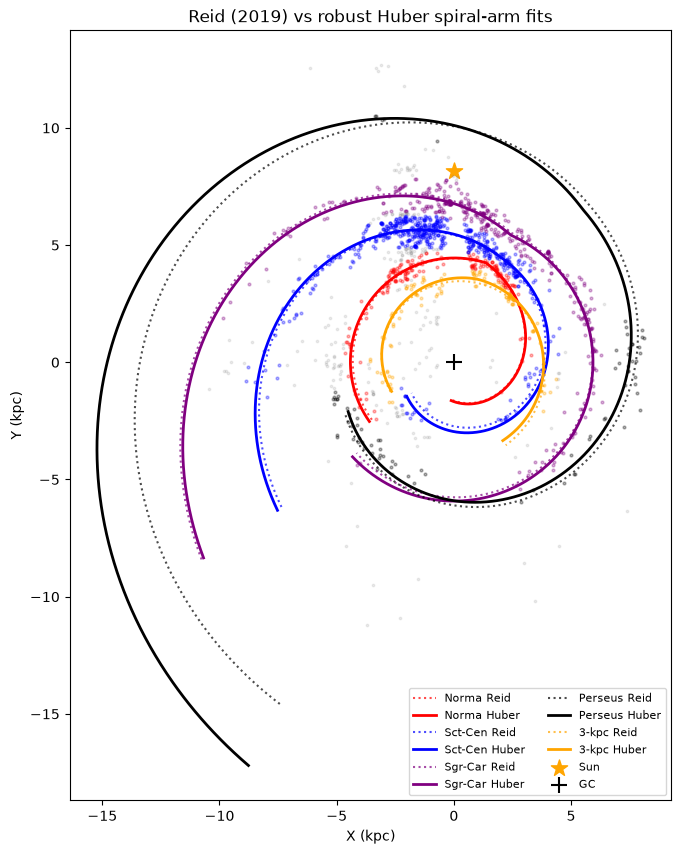

In [37]:
# Plot original Reid arms and robust Huber fits

fig, ax = plt.subplots(figsize=(10, 10))

# Lookup for robust fitting results
robust_lookup = {r["name"]: r for r in robust_results}

for name in arm_names:

    original = extended_arms[name]

    # Initial Reid geometry
    ax.plot(
        original["X"],
        original["Y"],
        color=colours[name],
        ls=":",
        lw=1.5,
        alpha=0.7,
        label=f"{name} Reid"
    )

    # Robust Huber fitted geometry
    result = robust_lookup.get(name)

    if result is not None:

        # Use the same unwrapped azimuth range as the Reid curve
        beta_grid = original["beta"]

        # Reid kink azimuth
        bkink = parameters[name][2]

        # Two-pitch-angle Huber model
        pitch = np.where(
            beta_grid <= bkink,
            result["pitch_low_fit"],
            result["pitch_high_fit"]
        )

        R_fit = result["Rkink_fit"] * np.exp(
            -np.radians(beta_grid - bkink)
            * np.tan(np.radians(pitch))
        )

        X_fit = R_fit * np.sin(np.radians(beta_grid))
        Y_fit = R_fit * np.cos(np.radians(beta_grid))

        ax.plot(
            X_fit,
            Y_fit,
            color=colours[name],
            ls="-",
            lw=2,
            label=f"{name} Huber"
        )

    # Clouds assigned to this arm
    subset = df_2[df_2["assigned_arm"] == name]

    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=4,
        color=colours[name],
        alpha=0.3,
        rasterized=True
    )

# Unassigned clouds
unassigned = df_2[df_2["assigned_arm"] == "Unassigned"]

ax.scatter(
    unassigned["X_kpc"],
    unassigned["Y_kpc"],
    s=3,
    color="grey",
    alpha=0.15,
    rasterized=True,
    zorder=2
)

# Sun and Galactic centre
ax.scatter(
    0, R0,
    marker="*",
    s=150,
    color="orange",
    label="Sun"
)

ax.scatter(
    0, 0,
    marker="+",
    s=120,
    color="black",
    label="GC"
)

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_aspect("equal")
ax.set_title("Reid (2019) vs robust Huber spiral-arm fits")
ax.legend(fontsize=8, ncol=2)

plt.show()

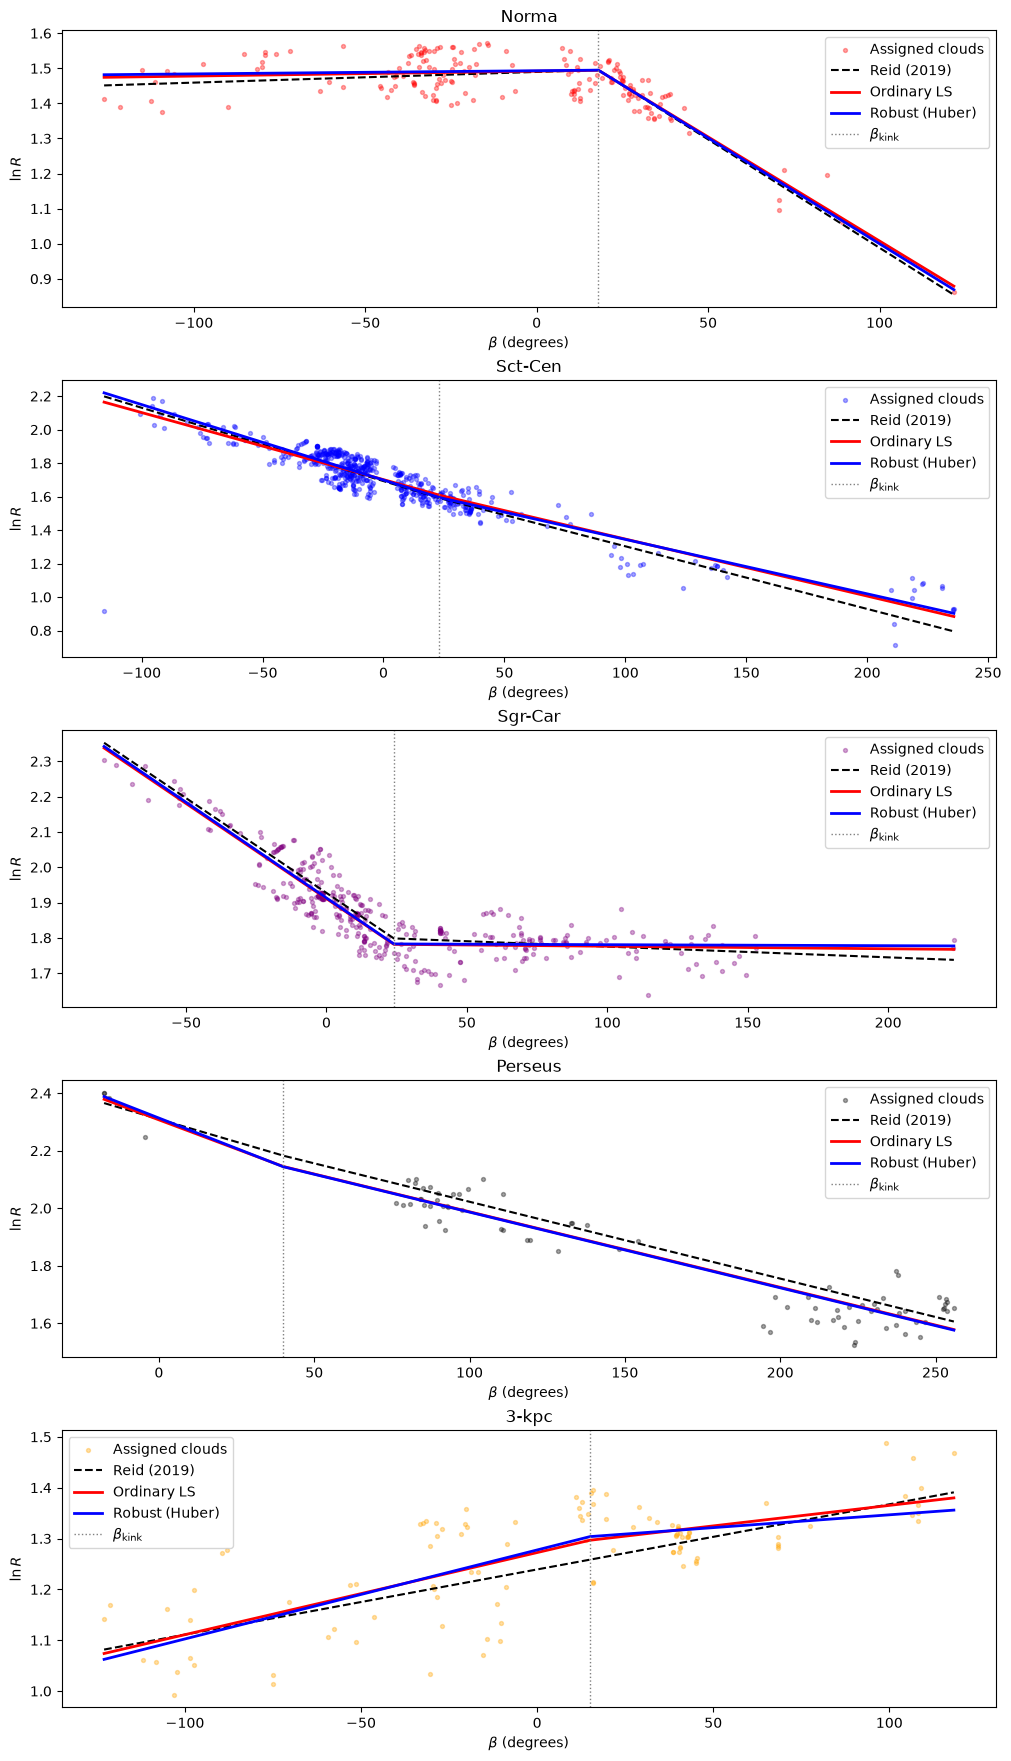

In [38]:
# Compare Reid, ordinary least squares, and robust fits

fig, axes = plt.subplots(
    len(arm_names), 1,
    figsize=(10, 3.5 * len(arm_names)),
    constrained_layout=True,
    squeeze=False
)

axes = axes.ravel()

# Create lookup dictionaries
fit_lookup = {r["name"]: r for r in fit_results}
robust_lookup = {r["name"]: r for r in robust_results}

for ax, name in zip(axes, arm_names):

    # Select valid clouds assigned to this arm
    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["beta_unwrapped_deg"])
        & np.isfinite(df_2["R_kpc"])
        & (df_2["R_kpc"] > 0)
    ]

    if subset.empty:
        ax.set_title(f"{name} (no assigned clouds)")
        continue

    beta_cloud = subset["beta_unwrapped_deg"].to_numpy()
    lnR_cloud = np.log(subset["R_kpc"].to_numpy())

    # Original Reid parameters
    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Grid spanning the observed cloud azimuths
    # Include the kink explicitly if it lies within the interval
    beta_grid = np.linspace(
        beta_cloud.min(),
        beta_cloud.max(),
        500
    )

    if beta_grid.min() < bkink < beta_grid.max():
        beta_grid = np.sort(np.r_[beta_grid, bkink])

    # Helper: continuous two-pitch logarithmic spiral
    def model_lnR(beta, Rkink, pitch_low, pitch_high):
        pitch = np.where(
            beta <= bkink,
            pitch_low,
            pitch_high
        )

        return (
            np.log(Rkink)
            - np.radians(beta - bkink)
            * np.tan(np.radians(pitch))
        )

    # Reid model
    lnR_reid = model_lnR(
        beta_grid, Rkink, p_low, p_high
    )

    # Plot molecular clouds
    ax.scatter(
        beta_cloud,
        lnR_cloud,
        s=8,
        color=colours[name],
        alpha=0.35,
        label="Assigned clouds"
    )

    # Plot Reid model
    ax.plot(
        beta_grid,
        lnR_reid,
        "k--",
        lw=1.5,
        label="Reid (2019)"
    )

    # Ordinary least-squares fit
    result = fit_lookup.get(name)

    if result is not None:

        lnR_fit = model_lnR(
            beta_grid,
            result["Rkink_fit"],
            result["pitch_low_fit"],
            result["pitch_high_fit"]
        )

        ax.plot(
            beta_grid,
            lnR_fit,
            color="red",
            lw=2,
            label="Ordinary LS"
        )

    # Robust Huber fit
    result_robust = robust_lookup.get(name)

    if result_robust is not None:

        lnR_rob = model_lnR(
            beta_grid,
            result_robust["Rkink_fit"],
            result_robust["pitch_low_fit"],
            result_robust["pitch_high_fit"]
        )

        ax.plot(
            beta_grid,
            lnR_rob,
            color="blue",
            lw=2,
            label="Robust (Huber)"
        )

    # Mark the kink if covered by the observations
    if beta_grid.min() <= bkink <= beta_grid.max():
        ax.axvline(
            bkink,
            color="gray",
            ls=":",
            lw=1,
            label=r"$\beta_{\rm kink}$"
        )

    ax.set_title(name)
    ax.set_xlabel(r"$\beta$ (degrees)")
    ax.set_ylabel(r"$\ln R$")

    ax.legend()

plt.show()


## Caution with these plots. For Perseus, Sct-Cen and Sgr-Car you see Reid missing them by a lot. That is a mistake, they are not at 
## azimuth -100 but actually at b > 100. if you take the same points, keep their lnR the same and move them to teh far right then
## they fit well!

In [39]:
## Investigate cloud-arm distance

# Look up fitted parameters
fit_lookup = {r["name"]: r for r in fit_results}
robust_lookup = {r["name"]: r for r in robust_results}

def spiral_xy(beta, bkink, Rkink, pitch_low, pitch_high):
    """
    Calculate Cartesian coordinates for a continuous
    two-pitch-angle logarithmic spiral.

    beta and pitch angles are in degrees.
    Radii and Cartesian coordinates are in kpc.
    """

    pitch = np.where(
        beta <= bkink,
        pitch_low,
        pitch_high
    )

    R = Rkink * np.exp(
        -np.radians(beta - bkink)
        * np.tan(np.radians(pitch))
    )

    X = R * np.sin(np.radians(beta))
    Y = R * np.cos(np.radians(beta))

    return np.column_stack([X, Y])


def cloud_arm_distances(cloud_xy, beta_grid,
                        bkink, Rkink, pitch_low, pitch_high):

    arm_xy = spiral_xy(
        beta_grid, bkink, Rkink, pitch_low, pitch_high
    )

    tree = cKDTree(arm_xy)

    distances, _ = tree.query(cloud_xy)

    return distances

In [40]:
# Initialize distance columns
for model in ["Reid", "OLS", "Huber"]:
    df_2[f"residual_{model}_kpc"] = np.nan

for name in arm_names:

    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["X_kpc"])
        & np.isfinite(df_2["Y_kpc"])
        & np.isfinite(df_2["beta_unwrapped_deg"])
    ]

    if subset.empty:
        continue

    cloud_xy = subset[["X_kpc", "Y_kpc"]].to_numpy()  ## Array for all clouds assigned to an arm, not single cloud

    beta_cloud = subset["beta_unwrapped_deg"].to_numpy()

    # Same comparison interval for all models
    beta_grid = np.linspace(
        beta_cloud.min() - 5,
        beta_cloud.max() + 5,
        10000
    )

    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    models = {
        "Reid": (Rkink, p_low, p_high)
    }

    if name in fit_lookup:
        r = fit_lookup[name]
        models["OLS"] = (
            r["Rkink_fit"],
            r["pitch_low_fit"],
            r["pitch_high_fit"]
        )

    if name in robust_lookup:
        r = robust_lookup[name]
        models["Huber"] = (
            r["Rkink_fit"],
            r["pitch_low_fit"],
            r["pitch_high_fit"]
        )

    for model_name, (radius, pitch1, pitch2) in models.items():

        distances = cloud_arm_distances(  ## Array of all distances ofclouds associated to arm, with arm
            cloud_xy,
            beta_grid,
            bkink,
            radius,
            pitch1,
            pitch2
        )

        df_2.loc[
            subset.index,
            f"residual_{model_name}_kpc"
        ] = distances

In [41]:
comparison = []

for name in arm_names:

    subset = df_2[df_2["assigned_arm"] == name]

    width = arm_widths[name]

    for model in ["Reid", "OLS", "Huber"]:

        d = subset[f"residual_{model}_kpc"].dropna().to_numpy()

        if len(d) == 0:
            continue

        comparison.append({
            "Arm": name,
            "Model": model,
            "N": len(d),
            "Median_kpc": np.median(d),
            "RMS_kpc": np.sqrt(np.mean(d**2)),
            "Within_1w_%": 100 * np.mean(d <= width),
            "Within_2w_%": 100 * np.mean(d <= 2 * width)
        })

comparison_table = pd.DataFrame(comparison)

print(comparison_table.round(3).to_string(index=False))

    Arm Model   N  Median_kpc  RMS_kpc  Within_1w_%  Within_2w_%
  Norma  Reid 177       0.152    0.205       45.198       76.271
  Norma   OLS 177       0.153    0.201       45.763       79.661
  Norma Huber 177       0.151    0.201       45.763       79.661
Sct-Cen  Reid 561       0.257    0.337       46.702       78.610
Sct-Cen   OLS 561       0.253    0.337       45.989       79.679
Sct-Cen Huber 561       0.236    0.332       47.950       79.857
Sgr-Car  Reid 359       0.207    0.330       59.889       87.465
Sgr-Car   OLS 359       0.212    0.319       60.167       90.529
Sgr-Car Huber 359       0.215    0.319       59.053       90.808
Perseus  Reid  81       0.317    0.427       53.086       90.123
Perseus   OLS  81       0.279    0.384       65.432       92.593
Perseus Huber  81       0.274    0.385       64.198       92.593
  3-kpc  Reid 106       0.170    0.265       53.774       76.415
  3-kpc   OLS 106       0.185    0.248       48.113       83.962
  3-kpc Huber 106       0

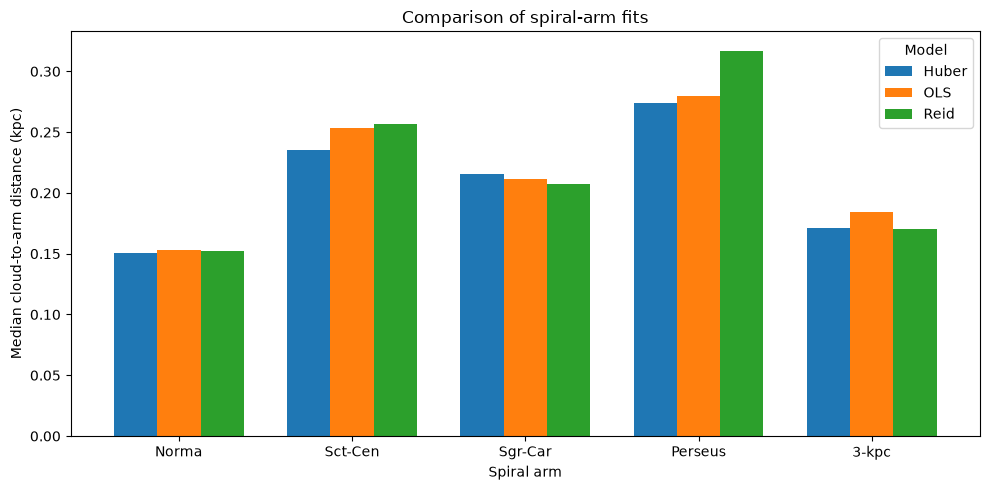

In [42]:
median_table = comparison_table.pivot(  # This turns the 15 x 1 column Median_kpc you see above into a 5 x 3 table, model vs arm
    index="Arm",
    columns="Model",
    values="Median_kpc"
)  

median_table = median_table.reindex(arm_names)

ax = median_table.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_ylabel("Median cloud-to-arm distance (kpc)")
ax.set_xlabel("Spiral arm")
ax.set_title("Comparison of spiral-arm fits")
ax.legend(title="Model")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

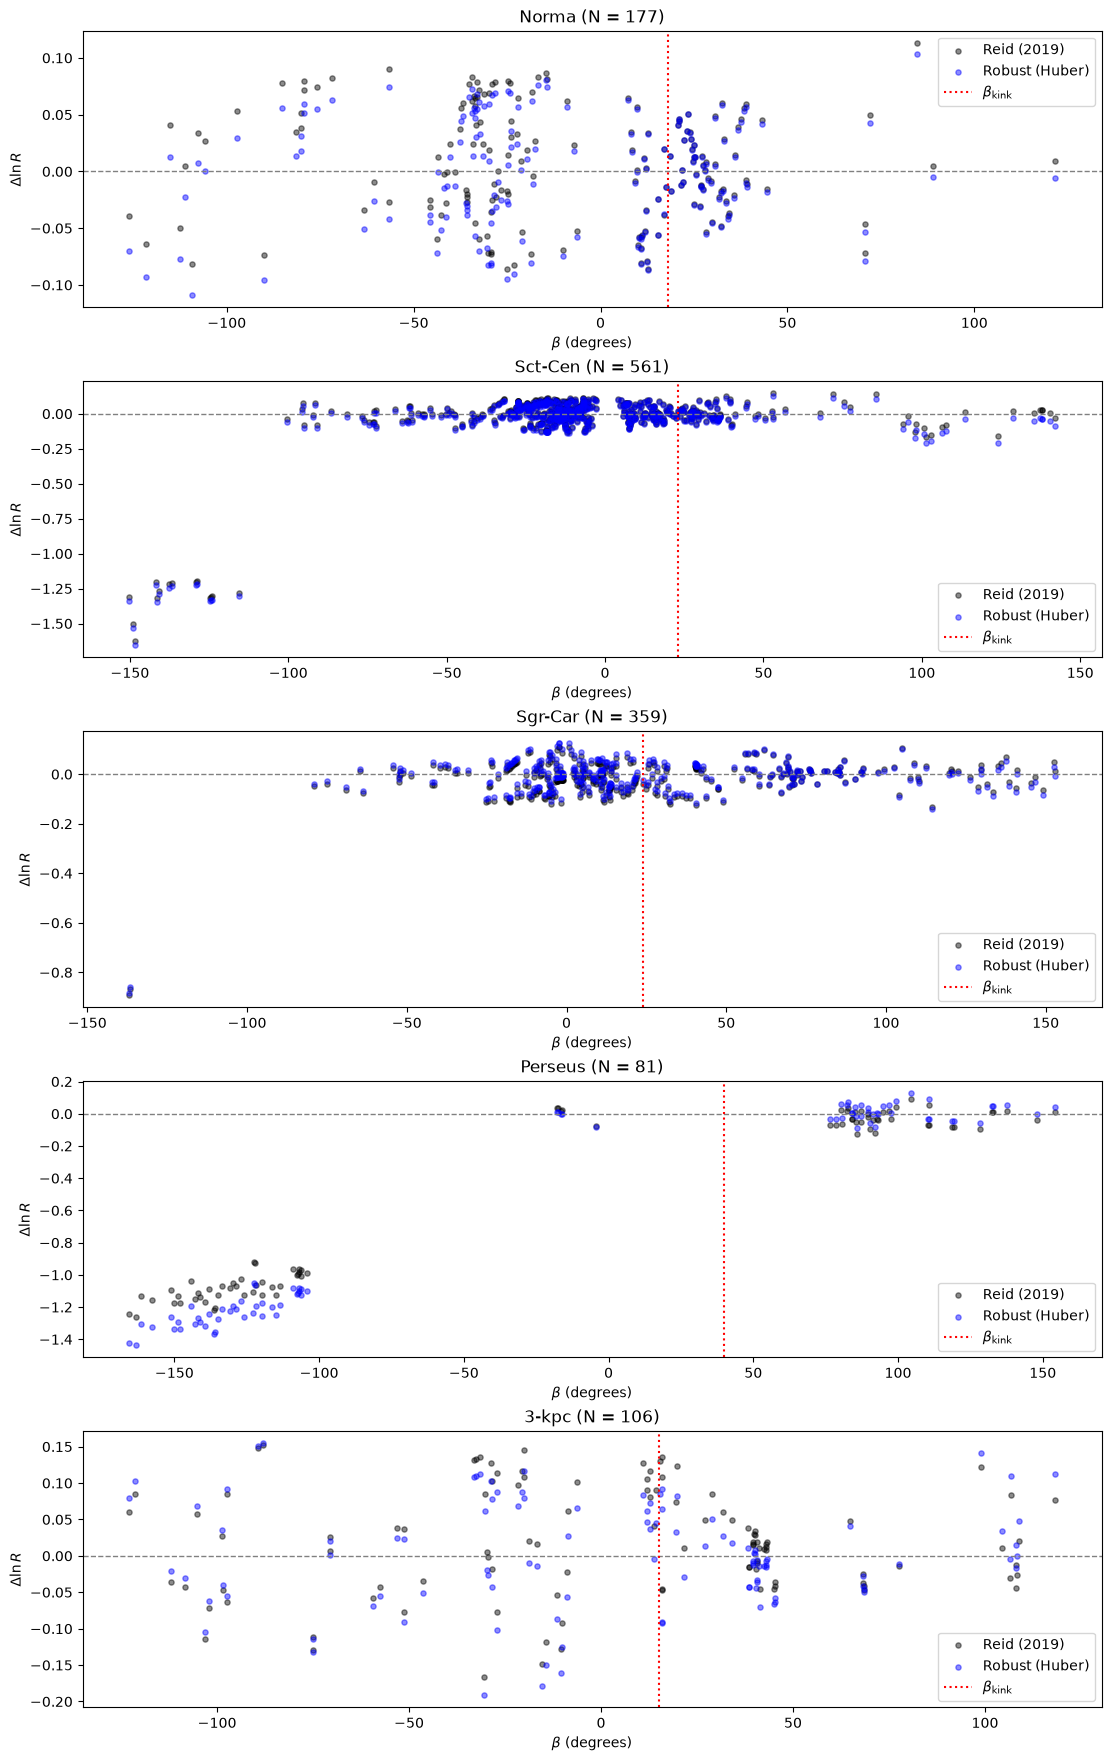

In [43]:
# Lookup for robust fitting results
# Plot the residuals, we want our points in the plots to be close to 0.
robust_lookup = {r["name"]: r for r in robust_results}

def spiral_lnR(beta, bkink, Rkink, pitch_low, pitch_high):
    """
    Logarithmic radius of a two-pitch-angle spiral.
    All angles are in degrees.
    """

    pitch = np.where(
        beta <= bkink,
        pitch_low,
        pitch_high
    )

    return (
        np.log(Rkink)
        - np.radians(beta - bkink)
        * np.tan(np.radians(pitch))
    )


fig, axes = plt.subplots(
    len(arm_names), 1,
    figsize=(11, 3.5 * len(arm_names)),
    constrained_layout=True,
    squeeze=False
)

axes = axes.ravel()

for ax, name in zip(axes, arm_names):

    # Select valid clouds
    subset = df_2.loc[
        (df_2["assigned_arm"] == name)
        & np.isfinite(df_2["beta_unwrapped_deg"])
        & np.isfinite(df_2["R_kpc"])
        & (df_2["R_kpc"] > 0)
    ]

    if subset.empty:
        ax.set_title(f"{name} (no assigned clouds)")
        continue

    beta = subset["beta_deg"].to_numpy()
    lnR_cloud = np.log(subset["R_kpc"].to_numpy())

    # Original Reid parameters
    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Reid predictions and residuals
    lnR_reid = spiral_lnR(
        beta, bkink, Rkink, p_low, p_high
    )

    residual_reid = lnR_cloud - lnR_reid

    ax.scatter(
        beta,
        residual_reid,
        s=14,
        color="black",
        alpha=0.45,
        label="Reid (2019)"
    )

    # Robust Huber predictions and residuals
    result = robust_lookup.get(name)

    if result is not None:

        lnR_huber = spiral_lnR(
            beta,
            bkink,
            result["Rkink_fit"],
            result["pitch_low_fit"],
            result["pitch_high_fit"]
        )

        residual_huber = lnR_cloud - lnR_huber

        ax.scatter(
            beta,
            residual_huber,
            s=14,
            color="blue",
            alpha=0.45,
            label="Robust (Huber)"
        )

    # Zero residual reference
    ax.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=1
    )

    # Reid kink azimuth
    if beta.min() <= bkink <= beta.max():
        ax.axvline(
            bkink,
            color="red",
            linestyle=":",
            linewidth=1.5,
            label=r"$\beta_{\rm kink}$"
        )

    ax.set_title(f"{name} (N = {len(subset)})")
    ax.set_xlabel(r"$\beta$ (degrees)")
    ax.set_ylabel(r"$\Delta \ln R$")

    ax.legend()

plt.show()

In [44]:
df_2.columns

Index(['Universal_ID', 'v_cen', 'x_cen', 'y_cen', 'final_distance', 'Mass',
       'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10',
       'X_kpc', 'Y_kpc', 'R_kpc', 'beta_deg', 'ln_R', 'dist_Norma_kpc',
       'dist_Sct-Cen_kpc', 'dist_Sgr-Car_kpc', 'dist_Perseus_kpc',
       'dist_3-kpc_kpc', 'nearest_arm', 'arm_distance_kpc', 'assigned_arm',
       'beta_unwrapped_deg', 'beta_winding', 'z_Norma', 'z_Sct-Cen',
       'z_Sgr-Car', 'z_Perseus', 'z_3-kpc', 'arm_z', 'second_best_z',
       'arm_separation_z', 'residual_Reid_kpc', 'residual_OLS_kpc',
       'residual_Huber_kpc'],
      dtype='str')